In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
!ls /content/drive/MyDrive/archive (4).zip

/bin/bash: -c: line 1: syntax error near unexpected token `('
/bin/bash: -c: line 1: `ls /content/drive/MyDrive/archive (4).zip'


In [ ]:
!unzip "/content/drive/MyDrive/archive (4).zip" -d /content/

Streaming output truncated to the last 5000 lines.
  inflating: /content/mvtec_Defect_detection_dataset/carpet/train/good/147.png  
  inflating: /content/mvtec_Defect_detection_dataset/carpet/train/good/148.png  
  inflating: /content/mvtec_Defect_detection_dataset/carpet/train/good/149.png  
  inflating: /content/mvtec_Defect_detection_dataset/carpet/train/good/150.png  
  inflating: /content/mvtec_Defect_detection_dataset/carpet/train/good/151.png  
  inflating: /content/mvtec_Defect_detection_dataset/carpet/train/good/152.png  
  inflating: /content/mvtec_Defect_detection_dataset/carpet/train/good/153.png  
  inflating: /content/mvtec_Defect_detection_dataset/carpet/train/good/154.png  
  inflating: /content/mvtec_Defect_detection_dataset/carpet/train/good/155.png  
  inflating: /content/mvtec_Defect_detection_dataset/carpet/train/good/156.png  
  inflating: /content/mvtec_Defect_detection_dataset/carpet/train/good/157.png  
  inflating: /content/mvtec_Defect_detection_dataset/carpe

In [ ]:
# ============================================================
# SETUP BLOCK — Run this FIRST before any model
# ============================================================
!pip install -q tensorflow scikit-learn seaborn matplotlib numpy

import os, warnings
warnings.filterwarnings('ignore')

import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

# GPU check
print("TF version:", tf.__version__)
gpus = tf.config.list_physical_devices('GPU')
print("GPU available:", gpus)
if gpus:
    tf.config.experimental.set_memory_growth(gpus[0], True)

# ── Paths ──────────────────────────────────────────────────
DATASET_PATH = "/content/mvtec_Defect_detection_dataset"
IMG_SIZE     = (224, 224)
BATCH_SIZE   = 32
SEED         = 42

# ── Discover all category folders ─────────────────────────
# MVTec layout: dataset/<category>/train/good, test/good, test/<defect_type>
# We flatten everything into good / defective for binary classification

import shutil
from pathlib import Path

BINARY_ROOT = "/content/mvtec_binary"
GOOD_DIR    = os.path.join(BINARY_ROOT, "good")
BAD_DIR     = os.path.join(BINARY_ROOT, "defective")

def build_binary_tree(src=DATASET_PATH, dst=BINARY_ROOT, force=False):
    """Symlink-free copy using hard links to save space."""
    if os.path.exists(dst) and not force:
        g = len(list(Path(GOOD_DIR).rglob("*.png"))) + len(list(Path(GOOD_DIR).rglob("*.jpg")))
        b = len(list(Path(BAD_DIR).rglob("*.png")))  + len(list(Path(BAD_DIR).rglob("*.jpg")))
        print(f"Binary tree already exists → good:{g}  defective:{b}")
        return
    os.makedirs(GOOD_DIR, exist_ok=True)
    os.makedirs(BAD_DIR,  exist_ok=True)
    idx = 0
    for root, dirs, files in os.walk(src):
        for fname in files:
            if not fname.lower().endswith(('.png','.jpg','.jpeg','.bmp')):
                continue
            fpath = os.path.join(root, fname)
            parts = Path(fpath).parts
            # A path segment named "good" → non-defective
            label = "good" if "good" in parts else "defective"
            dst_dir = GOOD_DIR if label == "good" else BAD_DIR
            ext  = os.path.splitext(fname)[1]
            dest = os.path.join(dst_dir, f"{idx:06d}{ext}")
            if not os.path.exists(dest):
                try:    os.link(fpath, dest)        # hard-link (no extra disk space)
                except: shutil.copy2(fpath, dest)   # fallback
            idx += 1
    g = len(os.listdir(GOOD_DIR))
    b = len(os.listdir(BAD_DIR))
    print(f"Binary tree built → good:{g}  defective:{b}")

build_binary_tree()

# ── tf.data loader factory (shared by every model) ────────
AUTOTUNE = tf.data.AUTOTUNE

def make_datasets(img_size=IMG_SIZE, batch_size=BATCH_SIZE,
                  val_split=0.15, test_split=0.15):
    """
    Returns (train_ds, val_ds, test_ds, class_names) using
    tf.keras.utils.image_dataset_from_directory — no full RAM load.
    """
    full_train = tf.keras.utils.image_dataset_from_directory(
        BINARY_ROOT,
        labels='inferred', label_mode='binary',
        image_size=img_size, batch_size=None,   # unbatched for splitting
        shuffle=True, seed=SEED,
        validation_split=val_split + test_split,
        subset='training'
    )
    full_val = tf.keras.utils.image_dataset_from_directory(
        BINARY_ROOT,
        labels='inferred', label_mode='binary',
        image_size=img_size, batch_size=None,
        shuffle=True, seed=SEED,
        validation_split=val_split + test_split,
        subset='validation'
    )
    class_names = full_train.class_names
    n_val_total = tf.data.experimental.cardinality(full_val).numpy()
    n_test      = int(n_val_total * (test_split / (val_split + test_split)))
    n_val       = n_val_total - n_test

    val_ds  = full_val.take(n_val)
    test_ds = full_val.skip(n_val)

    # Augmentation (train only)
    augment = tf.keras.Sequential([
        tf.keras.layers.RandomFlip("horizontal_and_vertical"),
        tf.keras.layers.RandomRotation(0.15),
        tf.keras.layers.RandomZoom(0.15),
        tf.keras.layers.RandomContrast(0.1),
    ])

    def preprocess_train(x, y):
        x = tf.cast(x, tf.float32) / 255.0
        x = augment(x, training=True)
        return x, y

    def preprocess_eval(x, y):
        x = tf.cast(x, tf.float32) / 255.0
        return x, y

    train_ds = (full_train.map(preprocess_train, AUTOTUNE)
                          .batch(batch_size).prefetch(AUTOTUNE).cache())
    val_ds   = (val_ds.map(preprocess_eval, AUTOTUNE)
                      .batch(batch_size).prefetch(AUTOTUNE).cache())
    test_ds  = (test_ds.map(preprocess_eval, AUTOTUNE)
                       .batch(batch_size).prefetch(AUTOTUNE))

    print(f"Classes : {class_names}")
    print(f"Train   : {tf.data.experimental.cardinality(full_train).numpy()} samples")
    print(f"Val     : {n_val}  |  Test: {n_test}")
    return train_ds, val_ds, test_ds, class_names

# ── Shared evaluation helper ───────────────────────────────
def evaluate_model(model, test_ds, model_name="Model"):
    y_true, y_pred_prob = [], []
    for x_batch, y_batch in test_ds:
        preds = model.predict(x_batch, verbose=0).flatten()
        y_pred_prob.extend(preds)
        y_true.extend(y_batch.numpy().flatten())
    y_true      = np.array(y_true, dtype=int)
    y_pred_prob = np.array(y_pred_prob)
    y_pred      = (y_pred_prob >= 0.5).astype(int)

    acc = accuracy_score(y_true, y_pred)
    print(f"\n{'='*55}")
    print(f"  {model_name} — Test Accuracy: {acc*100:.2f}%")
    print('='*55)
    print(classification_report(y_true, y_pred,
                                 target_names=["Good","Defective"]))
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(5,4))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=["Good","Defective"],
                yticklabels=["Good","Defective"])
    plt.title(f"{model_name} — Confusion Matrix")
    plt.ylabel("True"); plt.xlabel("Predicted")
    plt.tight_layout(); plt.show()
    return acc, y_true, y_pred

# Shared results store (populated by each model block)
ALL_RESULTS = {}
print("\n✅ Setup complete — proceed to Model blocks.")

TF version: 2.20.0
GPU available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Binary tree built → good:4096  defective:2516

✅ Setup complete — proceed to Model blocks.


Found 6612 files belonging to 2 classes.
Using 4629 files for training.
Found 6612 files belonging to 2 classes.
Using 1983 files for validation.
Classes : ['defective', 'good']
Train   : 4629 samples
Val     : 992  |  Test: 991
94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


Model: "ResNet50"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_2       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multiply (Multiply) │ (None, 224, 224,  │          0 │ input_layer_2[0]… │
│                     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item (GetItem)  │ (None, 224, 224)  │          0 │ multiply[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_1          │ (None, 224, 224)  │          0 │ multiply[0][0]    │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_2          │ (None, 224, 224)  │          0 │ multiply[0][0]    │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stack (Stack)       │ (None, 224, 224,  │          0 │ get_item[0][0],   │
│                     │ 3)                │            │ get_item_1[0][0], │
│                     │                   │            │ get_item_2[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 224, 224,  │          0 │ stack[0][0]       │
│                     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ resnet50            │ (None, 7, 7,      │ 23,587,712 │ add[0][0]         │
│ (Functional)        │ 2048)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 2048)      │          0 │ resnet50[0][0]    │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 2048)      │      8,192 │ global_average_p… │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 256)       │    524,544 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 256)       │          0 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 64)        │     16,448 │ dropout[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 1)         │         65 │ dense_1[0][0]     │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 24,136,961 (92.08 MB)

 Trainable params: 545,153 (2.08 MB)

 Non-trainable params: 23,591,808 (90.00 MB)

── Phase 1: Frozen backbone ──
Epoch 1/6
145/145 ━━━━━━━━━━━━━━━━━━━━ 203s 1s/step - accuracy: 0.7965 - loss: 0.5076 - val_accuracy: 0.8105 - val_loss: 0.3823 - learning_rate: 0.0010
Epoch 2/6
145/145 ━━━━━━━━━━━━━━━━━━━━ 15s 105ms/step - accuracy: 0.8408 - loss: 0.3886 - val_accuracy: 0.8105 - val_loss: 0.3660 - learning_rate: 0.0010
Epoch 3/6
145/145 ━━━━━━━━━━━━━━━━━━━━ 21s 108ms/step - accuracy: 0.8563 - loss: 0.3350 - val_accuracy: 0.8518 - val_loss: 0.3146 - learning_rate: 0.0010
Epoch 4/6
145/145 ━━━━━━━━━━━━━━━━━━━━ 16s 109ms/step - accuracy: 0.8786 - loss: 0.2883 - val_accuracy: 0.8720 - val_loss: 0.3023 - learning_rate: 0.0010
Epoch 5/6
145/145 ━━━━━━━━━━━━━━━━━━━━ 14s 99ms/step - accuracy: 0.8851 - loss: 0.2657 - val_accuracy: 0.8478 - val_loss: 0.3301 - learning_rate: 0.0010
Epoch 6/6
145/145 ━━━━━━━━━━━━━━━━━━━━ 0s 81ms/step - accuracy: 0.8868 - loss: 0.2593
Epoch 6: ReduceLROnPlateau reducing learning rate to 0.0003000000142492354.
145/145 ━━━━━━━━━━━━━━━━━━━━ 14s 98ms/st

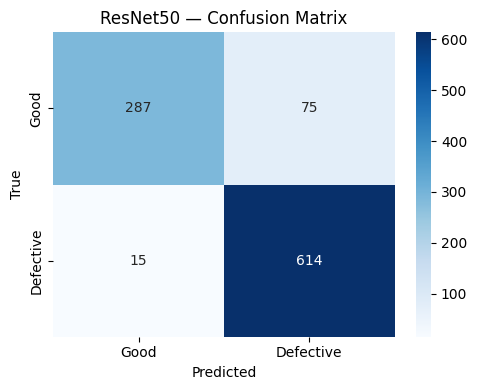

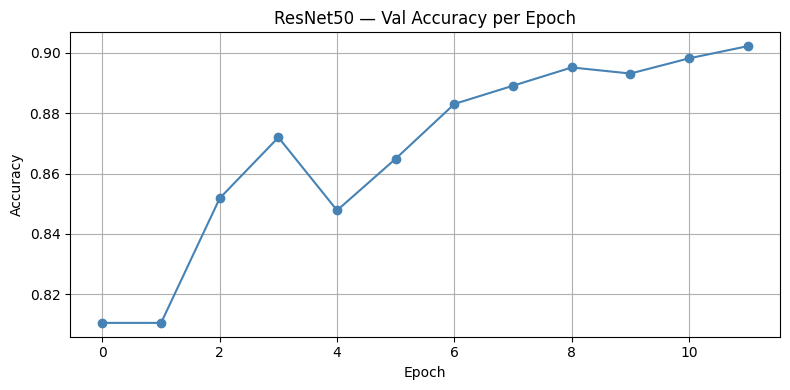


✅ ResNet50 saved → /content/ResNet50_best.keras


In [ ]:
# ============================================================
# MODEL 1: ResNet50 — Transfer Learning
# ============================================================
import os, warnings; warnings.filterwarnings('ignore')
import numpy as np, tensorflow as tf
import matplotlib.pyplot as plt

# ── Re-run setup if needed ─────────────────────────────────
# (skip if ALL_RESULTS already exists from Setup block)
# make_datasets / evaluate_model / ALL_RESULTS must be in scope

MODEL_NAME  = "ResNet50"
CHECKPOINT  = f"/content/{MODEL_NAME}_best.keras"

# 1. Data
train_ds, val_ds, test_ds, class_names = make_datasets()

# 2. Build model
base = tf.keras.applications.ResNet50(
    include_top=False, weights='imagenet', input_shape=(224,224,3))
base.trainable = False   # freeze backbone initially

inputs  = tf.keras.Input(shape=(224,224,3))
x       = tf.keras.applications.resnet50.preprocess_input(inputs * 255.)
x       = base(x, training=False)
x       = tf.keras.layers.GlobalAveragePooling2D()(x)
x       = tf.keras.layers.BatchNormalization()(x)
x       = tf.keras.layers.Dense(256, activation='relu')(x)
x       = tf.keras.layers.Dropout(0.4)(x)
x       = tf.keras.layers.Dense(64,  activation='relu')(x)
outputs = tf.keras.layers.Dense(1,   activation='sigmoid')(x)

model_r50 = tf.keras.Model(inputs, outputs, name=MODEL_NAME)
model_r50.summary()

# 3. Phase-1 training (frozen backbone)
model_r50.compile(
    optimizer=tf.keras.optimizers.Adam(1e-3),
    loss='binary_crossentropy',
    metrics=['accuracy'])

callbacks = [
    tf.keras.callbacks.EarlyStopping(patience=4, restore_best_weights=True, verbose=1),
    tf.keras.callbacks.ModelCheckpoint(CHECKPOINT, save_best_only=True, verbose=0),
    tf.keras.callbacks.ReduceLROnPlateau(factor=0.3, patience=2, min_lr=1e-6, verbose=1),
]

print("── Phase 1: Frozen backbone ──")
hist1 = model_r50.fit(train_ds, validation_data=val_ds,
                       epochs=6, callbacks=callbacks, verbose=1)

# 4. Phase-2: Fine-tune top 30 layers
base.trainable = True
for layer in base.layers[:-30]:
    layer.trainable = False

model_r50.compile(
    optimizer=tf.keras.optimizers.Adam(1e-5),
    loss='binary_crossentropy',
    metrics=['accuracy'])

print("── Phase 2: Fine-tuning top-30 layers ──")
hist2 = model_r50.fit(train_ds, validation_data=val_ds,
                       epochs=6, callbacks=callbacks, verbose=1)

# 5. Evaluate
acc_r50, yt_r50, yp_r50 = evaluate_model(model_r50, test_ds, MODEL_NAME)
ALL_RESULTS[MODEL_NAME] = acc_r50

# 6. Training curve
combined_acc = hist1.history['val_accuracy'] + hist2.history['val_accuracy']
plt.figure(figsize=(8,4))
plt.plot(combined_acc, marker='o', color='steelblue')
plt.title(f"{MODEL_NAME} — Val Accuracy per Epoch")
plt.xlabel("Epoch"); plt.ylabel("Accuracy"); plt.grid(True)
plt.tight_layout(); plt.show()

print(f"\n✅ {MODEL_NAME} saved → {CHECKPOINT}")

Found 6612 files belonging to 2 classes.
Using 4629 files for training.
Found 6612 files belonging to 2 classes.
Using 1983 files for validation.
Classes : ['defective', 'good']
Train   : 4629 samples
Val     : 992  |  Test: 991
9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "MobileNetV2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_5 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ multiply_1 (Multiply)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract (Subtract)             │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 1280)           │         5,120 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,427,201 (9.26 MB)

 Trainable params: 166,657 (651.00 KB)

 Non-trainable params: 2,260,544 (8.62 MB)

── Phase 1: Frozen backbone ──
Epoch 1/6
145/145 ━━━━━━━━━━━━━━━━━━━━ 207s 1s/step - accuracy: 0.8010 - loss: 0.4722 - val_accuracy: 0.8488 - val_loss: 0.3526 - learning_rate: 0.0010
Epoch 2/6
145/145 ━━━━━━━━━━━━━━━━━━━━ 12s 36ms/step - accuracy: 0.8559 - loss: 0.3259 - val_accuracy: 0.8780 - val_loss: 0.2896 - learning_rate: 0.0010
Epoch 3/6
145/145 ━━━━━━━━━━━━━━━━━━━━ 5s 35ms/step - accuracy: 0.8842 - loss: 0.2720 - val_accuracy: 0.8861 - val_loss: 0.2791 - learning_rate: 0.0010
Epoch 4/6
145/145 ━━━━━━━━━━━━━━━━━━━━ 6s 38ms/step - accuracy: 0.8985 - loss: 0.2407 - val_accuracy: 0.8901 - val_loss: 0.2763 - learning_rate: 0.0010
Epoch 5/6
145/145 ━━━━━━━━━━━━━━━━━━━━ 9s 32ms/step - accuracy: 0.9112 - loss: 0.2152 - val_accuracy: 0.8861 - val_loss: 0.2819 - learning_rate: 0.0010
Epoch 6/6
145/145 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - accuracy: 0.9147 - loss: 0.1961
Epoch 6: ReduceLROnPlateau reducing learning rate to 0.0003000000142492354.
145/145 ━━━━━━━━━━━━━━━━━━━━ 5s 34ms/step - ac

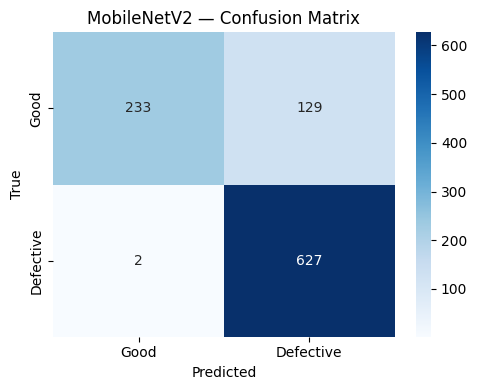

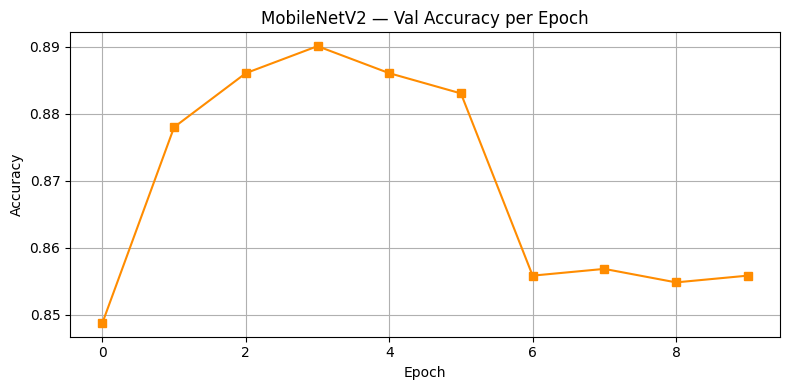


✅ MobileNetV2 saved → /content/MobileNetV2_best.keras


In [ ]:
# ============================================================
# MODEL 2: MobileNetV2 — Transfer Learning
# ============================================================
import os, warnings; warnings.filterwarnings('ignore')
import numpy as np, tensorflow as tf
import matplotlib.pyplot as plt

MODEL_NAME = "MobileNetV2"
CHECKPOINT = f"/content/{MODEL_NAME}_best.keras"

# 1. Data
train_ds, val_ds, test_ds, class_names = make_datasets(batch_size=32)

# 2. Build model
base = tf.keras.applications.MobileNetV2(
    include_top=False, weights='imagenet', input_shape=(224,224,3))
base.trainable = False

inputs  = tf.keras.Input(shape=(224,224,3))
x       = tf.keras.applications.mobilenet_v2.preprocess_input(inputs * 255.)
x       = base(x, training=False)
x       = tf.keras.layers.GlobalAveragePooling2D()(x)
x       = tf.keras.layers.BatchNormalization()(x)
x       = tf.keras.layers.Dense(128, activation='relu')(x)
x       = tf.keras.layers.Dropout(0.35)(x)
outputs = tf.keras.layers.Dense(1, activation='sigmoid')(x)

model_mv2 = tf.keras.Model(inputs, outputs, name=MODEL_NAME)
model_mv2.summary()

# 3. Phase-1 training
model_mv2.compile(
    optimizer=tf.keras.optimizers.Adam(1e-3),
    loss='binary_crossentropy',
    metrics=['accuracy'])

callbacks = [
    tf.keras.callbacks.EarlyStopping(patience=4, restore_best_weights=True, verbose=1),
    tf.keras.callbacks.ModelCheckpoint(CHECKPOINT, save_best_only=True, verbose=0),
    tf.keras.callbacks.ReduceLROnPlateau(factor=0.3, patience=2, min_lr=1e-6, verbose=1),
]

print("── Phase 1: Frozen backbone ──")
hist1 = model_mv2.fit(train_ds, validation_data=val_ds,
                       epochs=6, callbacks=callbacks, verbose=1)

# 4. Phase-2: unfreeze last 20 layers
base.trainable = True
for layer in base.layers[:-20]:
    layer.trainable = False

model_mv2.compile(
    optimizer=tf.keras.optimizers.Adam(2e-5),
    loss='binary_crossentropy',
    metrics=['accuracy'])

print("── Phase 2: Fine-tuning top-20 layers ──")
hist2 = model_mv2.fit(train_ds, validation_data=val_ds,
                       epochs=6, callbacks=callbacks, verbose=1)

# 5. Evaluate
acc_mv2, yt_mv2, yp_mv2 = evaluate_model(model_mv2, test_ds, MODEL_NAME)
ALL_RESULTS[MODEL_NAME] = acc_mv2

# 6. Training curve
combined_acc = hist1.history['val_accuracy'] + hist2.history['val_accuracy']
plt.figure(figsize=(8,4))
plt.plot(combined_acc, marker='s', color='darkorange')
plt.title(f"{MODEL_NAME} — Val Accuracy per Epoch")
plt.xlabel("Epoch"); plt.ylabel("Accuracy"); plt.grid(True)
plt.tight_layout(); plt.show()

print(f"\n✅ {MODEL_NAME} saved → {CHECKPOINT}")

Found 6612 files belonging to 2 classes.
Using 4629 files for training.
Found 6612 files belonging to 2 classes.
Using 1983 files for validation.
Classes : ['defective', 'good']
Train   : 4629 samples
Val     : 992  |  Test: 991


Model: "CustomCNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_7 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 224, 224, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 224, 224, 32)   │         9,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 224, 224, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spatial_dropout2d               │ (None, 112, 112, 32)   │             0 │
│ (SpatialDropout2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 112, 112, 64)   │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 112, 112, 64)   │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spatial_dropout2d_1             │ (None, 56, 56, 64)     │             0 │
│ (SpatialDropout2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 56, 56, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 56, 56, 128)    │       147,456 │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 4,866,017 (18.56 MB)

 Trainable params: 4,862,049 (18.55 MB)

 Non-trainable params: 3,968 (15.50 KB)

Epoch 1/12
145/145 ━━━━━━━━━━━━━━━━━━━━ 229s 1s/step - accuracy: 0.7695 - loss: 0.5186 - val_accuracy: 0.6331 - val_loss: 0.6615 - learning_rate: 0.0010
Epoch 2/12
145/145 ━━━━━━━━━━━━━━━━━━━━ 66s 179ms/step - accuracy: 0.7941 - loss: 0.4882 - val_accuracy: 0.6331 - val_loss: 0.6842 - learning_rate: 0.0010
Epoch 3/12
145/145 ━━━━━━━━━━━━━━━━━━━━ 26s 182ms/step - accuracy: 0.8006 - loss: 0.4732 - val_accuracy: 0.8125 - val_loss: 0.4671 - learning_rate: 0.0010
Epoch 4/12
145/145 ━━━━━━━━━━━━━━━━━━━━ 25s 175ms/step - accuracy: 0.7982 - loss: 0.4788 - val_accuracy: 0.7873 - val_loss: 0.5719 - learning_rate: 0.0010
Epoch 5/12
145/145 ━━━━━━━━━━━━━━━━━━━━ 0s 168ms/step - accuracy: 0.8006 - loss: 0.4782
Epoch 5: ReduceLROnPlateau reducing learning rate to 0.0004000000189989805.
145/145 ━━━━━━━━━━━━━━━━━━━━ 26s 176ms/step - accuracy: 0.8030 - loss: 0.4726 - val_accuracy: 0.8044 - val_loss: 0.4911 - learning_rate: 0.0010
Epoch 6/12
145/145 ━━━━━━━━━━━━━━━━━━━━ 26s 180ms/step - accuracy: 0.8047 

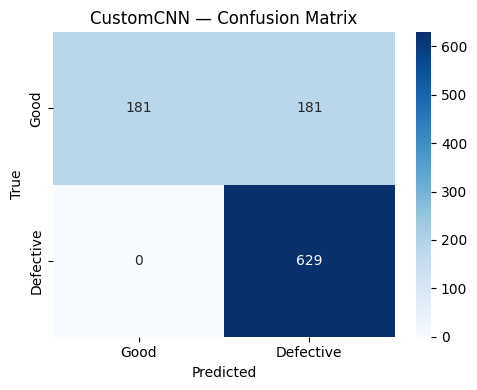

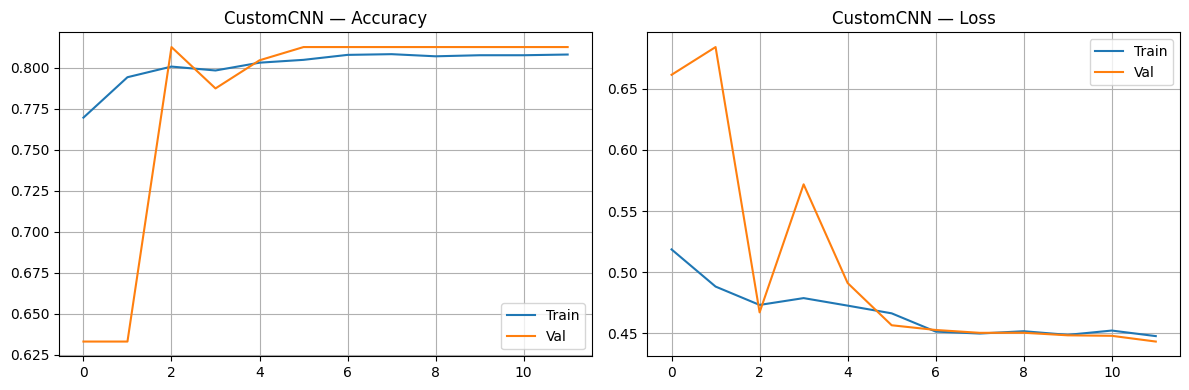


✅ CustomCNN saved → /content/CustomCNN_best.keras


In [ ]:
# ============================================================
# MODEL 3: Custom CNN — 4 Convolutional Blocks
# ============================================================
import os, warnings; warnings.filterwarnings('ignore')
import numpy as np, tensorflow as tf
import matplotlib.pyplot as plt

MODEL_NAME = "CustomCNN"
CHECKPOINT = f"/content/{MODEL_NAME}_best.keras"

# 1. Data
train_ds, val_ds, test_ds, class_names = make_datasets(batch_size=32)

# 2. Build model — 4 conv blocks + residual-style skip
def conv_block(x, filters, kernel=3, pool=True):
    x = tf.keras.layers.Conv2D(filters, kernel, padding='same', use_bias=False)(x)
    x = tf.keras.layers.BatchNormalization()(x)
    x = tf.keras.layers.Activation('relu')(x)
    x = tf.keras.layers.Conv2D(filters, kernel, padding='same', use_bias=False)(x)
    x = tf.keras.layers.BatchNormalization()(x)
    x = tf.keras.layers.Activation('relu')(x)
    if pool:
        x = tf.keras.layers.MaxPooling2D(2)(x)
    x = tf.keras.layers.SpatialDropout2D(0.2)(x)
    return x

inputs = tf.keras.Input(shape=(224,224,3))

# Block 1 — 32 filters
x = conv_block(inputs, 32)   # → 112×112

# Block 2 — 64 filters
x = conv_block(x, 64)        # → 56×56

# Block 3 — 128 filters
x = conv_block(x, 128)       # → 28×28

# Block 4 — 256 filters
x = conv_block(x, 256)       # → 14×14

# Block 5 — 512 filters (no pooling)
x = conv_block(x, 512, pool=False)

# Head
x = tf.keras.layers.GlobalAveragePooling2D()(x)
x = tf.keras.layers.Dense(256, activation='relu')(x)
x = tf.keras.layers.Dropout(0.5)(x)
x = tf.keras.layers.Dense(64,  activation='relu')(x)
x = tf.keras.layers.Dropout(0.3)(x)
outputs = tf.keras.layers.Dense(1, activation='sigmoid')(x)

model_cnn = tf.keras.Model(inputs, outputs, name=MODEL_NAME)
model_cnn.summary()

# 3. Compile
model_cnn.compile(
    optimizer=tf.keras.optimizers.AdamW(learning_rate=1e-3, weight_decay=1e-4),
    loss='binary_crossentropy',
    metrics=['accuracy'])

callbacks = [
    tf.keras.callbacks.EarlyStopping(patience=4, restore_best_weights=True, verbose=1),
    tf.keras.callbacks.ModelCheckpoint(CHECKPOINT, save_best_only=True, verbose=0),
    tf.keras.callbacks.ReduceLROnPlateau(factor=0.4, patience=2, min_lr=1e-6, verbose=1),
]

# 4. Train
hist = model_cnn.fit(train_ds, validation_data=val_ds,
                      epochs=12, callbacks=callbacks, verbose=1)

# 5. Evaluate
acc_cnn, yt_cnn, yp_cnn = evaluate_model(model_cnn, test_ds, MODEL_NAME)
ALL_RESULTS[MODEL_NAME] = acc_cnn

# 6. Training curves
fig, axes = plt.subplots(1, 2, figsize=(12,4))
axes[0].plot(hist.history['accuracy'],     label='Train')
axes[0].plot(hist.history['val_accuracy'], label='Val')
axes[0].set_title(f"{MODEL_NAME} — Accuracy"); axes[0].legend(); axes[0].grid(True)
axes[1].plot(hist.history['loss'],     label='Train')
axes[1].plot(hist.history['val_loss'], label='Val')
axes[1].set_title(f"{MODEL_NAME} — Loss"); axes[1].legend(); axes[1].grid(True)
plt.tight_layout(); plt.show()

print(f"\n✅ {MODEL_NAME} saved → {CHECKPOINT}")

Found 6612 files belonging to 2 classes.
Using 4629 files for training.
Found 6612 files belonging to 2 classes.
Using 1983 files for validation.
Classes : ['defective', 'good']
Train   : 4629 samples
Val     : 992  |  Test: 991


Model: "CNN_LSTM"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_9 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_10 (Conv2D)              │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_12          │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 56, 56, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 56, 56, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_13          │ (None, 56, 56, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_12 (Conv2D)              │ (None, 14, 14, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_14          │ (None, 14, 14, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ (None, 7, 896)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 7, 128)         │       524,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 64)             │        49,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 672,577 (2.57 MB)

 Trainable params: 672,129 (2.56 MB)

 Non-trainable params: 448 (1.75 KB)

Epoch 1/10
290/290 ━━━━━━━━━━━━━━━━━━━━ 161s 518ms/step - accuracy: 0.7939 - loss: 0.4711 - val_accuracy: 0.6341 - val_loss: 0.6881 - learning_rate: 5.0000e-04
Epoch 2/10
290/290 ━━━━━━━━━━━━━━━━━━━━ 12s 40ms/step - accuracy: 0.8084 - loss: 0.4508 - val_accuracy: 0.8125 - val_loss: 0.4362 - learning_rate: 5.0000e-04
Epoch 3/10
290/290 ━━━━━━━━━━━━━━━━━━━━ 11s 39ms/step - accuracy: 0.8090 - loss: 0.4427 - val_accuracy: 0.8125 - val_loss: 0.4380 - learning_rate: 5.0000e-04
Epoch 4/10
290/290 ━━━━━━━━━━━━━━━━━━━━ 11s 39ms/step - accuracy: 0.8099 - loss: 0.4375 - val_accuracy: 0.8125 - val_loss: 0.4298 - learning_rate: 5.0000e-04
Epoch 5/10
290/290 ━━━━━━━━━━━━━━━━━━━━ 11s 38ms/step - accuracy: 0.8095 - loss: 0.4373 - val_accuracy: 0.8125 - val_loss: 0.4300 - learning_rate: 5.0000e-04
Epoch 6/10
289/290 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step - accuracy: 0.8107 - loss: 0.4320
Epoch 6: ReduceLROnPlateau reducing learning rate to 0.0001500000071246177.
290/290 ━━━━━━━━━━━━━━━━━━━━ 11s 39ms/step - 

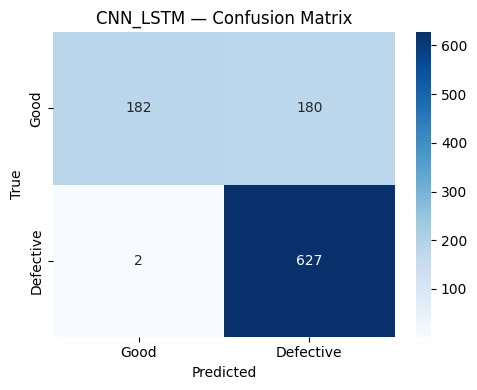

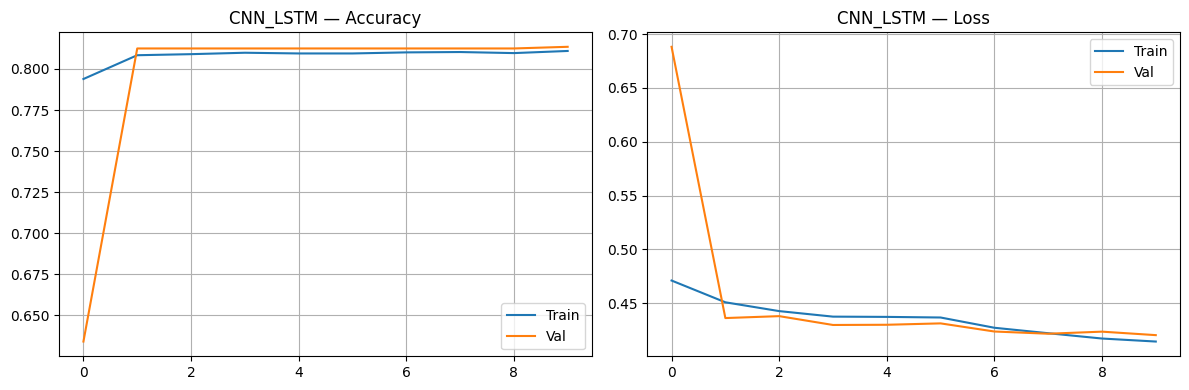


✅ CNN_LSTM saved → /content/CNN_LSTM_best.keras


In [ ]:
# ============================================================
# MODEL 4: CNN + LSTM
# Converts spatial CNN feature maps into temporal sequences
# ============================================================
import os, warnings; warnings.filterwarnings('ignore')
import numpy as np, tensorflow as tf
import matplotlib.pyplot as plt

MODEL_NAME = "CNN_LSTM"
CHECKPOINT = f"/content/{MODEL_NAME}_best.keras"

# 1. Data — use smaller batch due to higher memory for RNN
train_ds, val_ds, test_ds, class_names = make_datasets(batch_size=16)

# 2. Build CNN+LSTM
# Strategy: CNN extracts feature maps → reshape rows as time-steps → LSTM
inputs = tf.keras.Input(shape=(224, 224, 3))

# ── CNN feature extractor ──────────────────────────────────
x = tf.keras.layers.Conv2D(32,  3, padding='same', activation='relu')(inputs)
x = tf.keras.layers.BatchNormalization()(x)
x = tf.keras.layers.MaxPooling2D(4)(x)          # → 56×56×32

x = tf.keras.layers.Conv2D(64,  3, padding='same', activation='relu')(x)
x = tf.keras.layers.BatchNormalization()(x)
x = tf.keras.layers.MaxPooling2D(4)(x)          # → 14×14×64

x = tf.keras.layers.Conv2D(128, 3, padding='same', activation='relu')(x)
x = tf.keras.layers.BatchNormalization()(x)
x = tf.keras.layers.MaxPooling2D(2)(x)          # → 7×7×128

# ── Reshape: (7,7,128) → (7, 7*128=896) — rows as time steps ──
x = tf.keras.layers.Reshape((7, 7 * 128))(x)   # (batch, 7, 896)

# ── LSTM ───────────────────────────────────────────────────
x = tf.keras.layers.LSTM(128, return_sequences=True, dropout=0.3)(x)
x = tf.keras.layers.LSTM(64,  dropout=0.3)(x)

# ── Head ───────────────────────────────────────────────────
x = tf.keras.layers.Dense(64, activation='relu')(x)
x = tf.keras.layers.Dropout(0.4)(x)
outputs = tf.keras.layers.Dense(1, activation='sigmoid')(x)

model_lstm = tf.keras.Model(inputs, outputs, name=MODEL_NAME)
model_lstm.summary()

# 3. Compile
model_lstm.compile(
    optimizer=tf.keras.optimizers.Adam(5e-4),
    loss='binary_crossentropy',
    metrics=['accuracy'])

callbacks = [
    tf.keras.callbacks.EarlyStopping(patience=4, restore_best_weights=True, verbose=1),
    tf.keras.callbacks.ModelCheckpoint(CHECKPOINT, save_best_only=True, verbose=0),
    tf.keras.callbacks.ReduceLROnPlateau(factor=0.3, patience=2, min_lr=1e-6, verbose=1),
]

# 4. Train
hist = model_lstm.fit(train_ds, validation_data=val_ds,
                       epochs=10, callbacks=callbacks, verbose=1)

# 5. Evaluate
acc_lstm, yt_lstm, yp_lstm = evaluate_model(model_lstm, test_ds, MODEL_NAME)
ALL_RESULTS[MODEL_NAME] = acc_lstm

# 6. Curves
fig, axes = plt.subplots(1, 2, figsize=(12,4))
axes[0].plot(hist.history['accuracy'],     label='Train')
axes[0].plot(hist.history['val_accuracy'], label='Val')
axes[0].set_title(f"{MODEL_NAME} — Accuracy"); axes[0].legend(); axes[0].grid(True)
axes[1].plot(hist.history['loss'],     label='Train')
axes[1].plot(hist.history['val_loss'], label='Val')
axes[1].set_title(f"{MODEL_NAME} — Loss"); axes[1].legend(); axes[1].grid(True)
plt.tight_layout(); plt.show()

print(f"\n✅ {MODEL_NAME} saved → {CHECKPOINT}")

Found 6612 files belonging to 2 classes.
Using 4629 files for training.
Found 6612 files belonging to 2 classes.
Using 1983 files for validation.
Classes : ['defective', 'good']
Train   : 4629 samples
Val     : 992  |  Test: 991


Model: "CNN_GRU"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_11 (InputLayer)     │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_13 (Conv2D)              │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_15          │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 56, 56, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_14 (Conv2D)              │ (None, 56, 56, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_16          │ (None, 56, 56, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_15 (Conv2D)              │ (None, 14, 14, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_17          │ (None, 14, 14, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_9 (MaxPooling2D)  │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape_1 (Reshape)             │ (None, 7, 896)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ (None, 7, 256)         │       787,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru_1 (GRU)                     │ (None, 64)             │        61,824 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 948,161 (3.62 MB)

 Trainable params: 947,713 (3.62 MB)

 Non-trainable params: 448 (1.75 KB)

Epoch 1/10
290/290 ━━━━━━━━━━━━━━━━━━━━ 161s 535ms/step - accuracy: 0.7917 - loss: 0.4762 - val_accuracy: 0.6946 - val_loss: 0.5773 - learning_rate: 5.0000e-04
Epoch 2/10
290/290 ━━━━━━━━━━━━━━━━━━━━ 58s 41ms/step - accuracy: 0.8079 - loss: 0.4518 - val_accuracy: 0.8125 - val_loss: 0.4381 - learning_rate: 5.0000e-04
Epoch 3/10
290/290 ━━━━━━━━━━━━━━━━━━━━ 12s 41ms/step - accuracy: 0.8090 - loss: 0.4437 - val_accuracy: 0.8125 - val_loss: 0.4325 - learning_rate: 5.0000e-04
Epoch 4/10
290/290 ━━━━━━━━━━━━━━━━━━━━ 12s 41ms/step - accuracy: 0.8084 - loss: 0.4413 - val_accuracy: 0.8125 - val_loss: 0.4342 - learning_rate: 5.0000e-04
Epoch 5/10
290/290 ━━━━━━━━━━━━━━━━━━━━ 12s 41ms/step - accuracy: 0.8095 - loss: 0.4385 - val_accuracy: 0.8125 - val_loss: 0.4310 - learning_rate: 5.0000e-04
Epoch 6/10
290/290 ━━━━━━━━━━━━━━━━━━━━ 12s 41ms/step - accuracy: 0.8088 - loss: 0.4312 - val_accuracy: 0.8125 - val_loss: 0.4274 - learning_rate: 5.0000e-04
Epoch 7/10
290/290 ━━━━━━━━━━━━━━━━━━━━ 12s 40ms/s

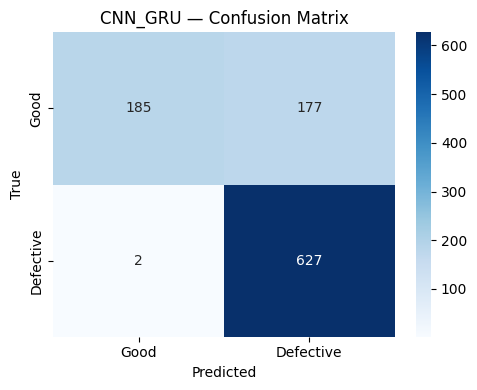

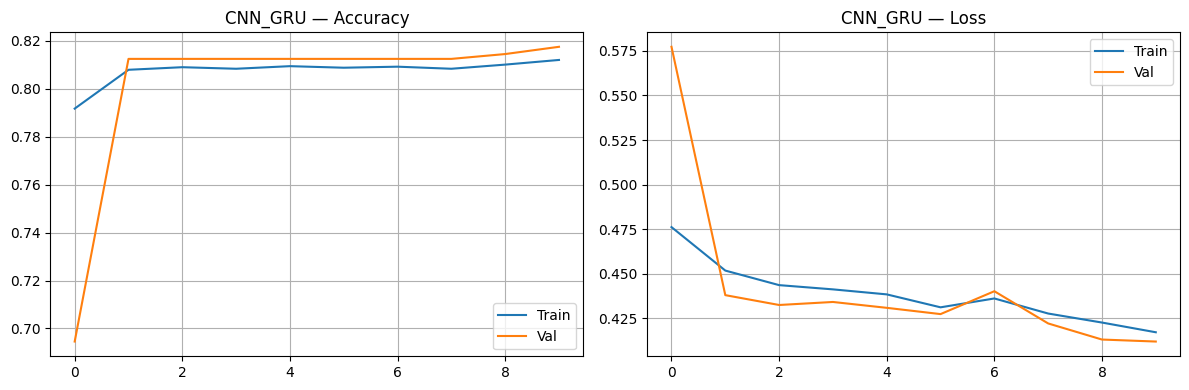


✅ CNN_GRU saved → /content/CNN_GRU_best.keras


In [ ]:
# ============================================================
# MODEL 5: CNN + GRU
# GRU is faster than LSTM with comparable performance
# ============================================================
import os, warnings; warnings.filterwarnings('ignore')
import numpy as np, tensorflow as tf
import matplotlib.pyplot as plt

MODEL_NAME = "CNN_GRU"
CHECKPOINT = f"/content/{MODEL_NAME}_best.keras"

# 1. Data
train_ds, val_ds, test_ds, class_names = make_datasets(batch_size=16)

# 2. Build CNN+GRU
inputs = tf.keras.Input(shape=(224, 224, 3))

# ── CNN feature extractor (shared backbone) ────────────────
x = tf.keras.layers.Conv2D(32,  3, padding='same', activation='relu')(inputs)
x = tf.keras.layers.BatchNormalization()(x)
x = tf.keras.layers.MaxPooling2D(4)(x)          # → 56×56×32

x = tf.keras.layers.Conv2D(64,  3, padding='same', activation='relu')(x)
x = tf.keras.layers.BatchNormalization()(x)
x = tf.keras.layers.MaxPooling2D(4)(x)          # → 14×14×64

x = tf.keras.layers.Conv2D(128, 3, padding='same', activation='relu')(x)
x = tf.keras.layers.BatchNormalization()(x)
x = tf.keras.layers.MaxPooling2D(2)(x)          # → 7×7×128

# ── Reshape to sequence: (7, 896) ─────────────────────────
x = tf.keras.layers.Reshape((7, 7 * 128))(x)

# ── Bidirectional GRU for richer context ──────────────────
x = tf.keras.layers.Bidirectional(
        tf.keras.layers.GRU(128, return_sequences=True, dropout=0.3))(x)
x = tf.keras.layers.GRU(64, dropout=0.3)(x)

# ── Attention-like squeeze ─────────────────────────────────
x = tf.keras.layers.Dense(64, activation='relu')(x)
x = tf.keras.layers.Dropout(0.4)(x)
outputs = tf.keras.layers.Dense(1, activation='sigmoid')(x)

model_gru = tf.keras.Model(inputs, outputs, name=MODEL_NAME)
model_gru.summary()

# 3. Compile
model_gru.compile(
    optimizer=tf.keras.optimizers.Adam(5e-4),
    loss='binary_crossentropy',
    metrics=['accuracy'])

callbacks = [
    tf.keras.callbacks.EarlyStopping(patience=4, restore_best_weights=True, verbose=1),
    tf.keras.callbacks.ModelCheckpoint(CHECKPOINT, save_best_only=True, verbose=0),
    tf.keras.callbacks.ReduceLROnPlateau(factor=0.3, patience=2, min_lr=1e-6, verbose=1),
]

# 4. Train
hist = model_gru.fit(train_ds, validation_data=val_ds,
                      epochs=10, callbacks=callbacks, verbose=1)

# 5. Evaluate
acc_gru, yt_gru, yp_gru = evaluate_model(model_gru, test_ds, MODEL_NAME)
ALL_RESULTS[MODEL_NAME] = acc_gru

# 6. Curves
fig, axes = plt.subplots(1, 2, figsize=(12,4))
axes[0].plot(hist.history['accuracy'],     label='Train')
axes[0].plot(hist.history['val_accuracy'], label='Val')
axes[0].set_title(f"{MODEL_NAME} — Accuracy"); axes[0].legend(); axes[0].grid(True)
axes[1].plot(hist.history['loss'],     label='Train')
axes[1].plot(hist.history['val_loss'], label='Val')
axes[1].set_title(f"{MODEL_NAME} — Loss"); axes[1].legend(); axes[1].grid(True)
plt.tight_layout(); plt.show()

print(f"\n✅ {MODEL_NAME} saved → {CHECKPOINT}")

Feature encoder output dim: 1280
Found 6612 files belonging to 2 classes.
Using 4629 files for training.
Found 6612 files belonging to 2 classes.
Using 1983 files for validation.
Classes : ['defective', 'good']
Train   : 4629 samples
Val     : 992  |  Test: 991
Extracting train features …
Extracting test features …
Train:4629  Test:991


Model: "Q_Network"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_12 (Dense)                │ (None, 512)            │       655,872 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_18          │ (None, 512)            │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_14 (Dense)                │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_15 (Dense)                │ (None, 2)              │           258 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 822,402 (3.14 MB)

 Trainable params: 821,378 (3.13 MB)

 Non-trainable params: 1,024 (4.00 KB)

Episode 1/8 | Acc:50.3%  Reward:25  ε:0.995
Episode 2/8 | Acc:50.0%  Reward:-3  ε:0.990
Episode 3/8 | Acc:50.0%  Reward:3  ε:0.985
Episode 4/8 | Acc:49.9%  Reward:-9  ε:0.980
Episode 5/8 | Acc:50.5%  Reward:47  ε:0.975
Episode 6/8 | Acc:51.3%  Reward:121  ε:0.970
Episode 7/8 | Acc:50.1%  Reward:7  ε:0.966
Episode 8/8 | Acc:50.0%  Reward:1  ε:0.961

  DQN — Test Accuracy: 48.13%
              precision    recall  f1-score   support

        Good       0.41      0.80      0.54       377
   Defective       0.70      0.29      0.41       614

    accuracy                           0.48       991
   macro avg       0.55      0.54      0.47       991
weighted avg       0.59      0.48      0.46       991



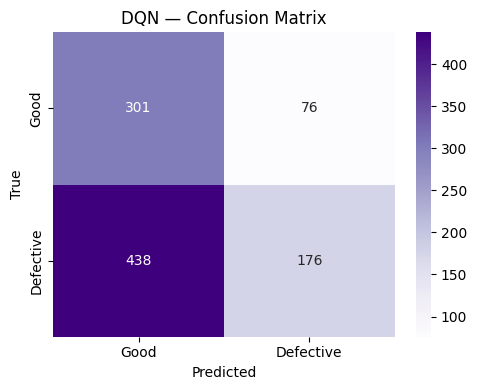

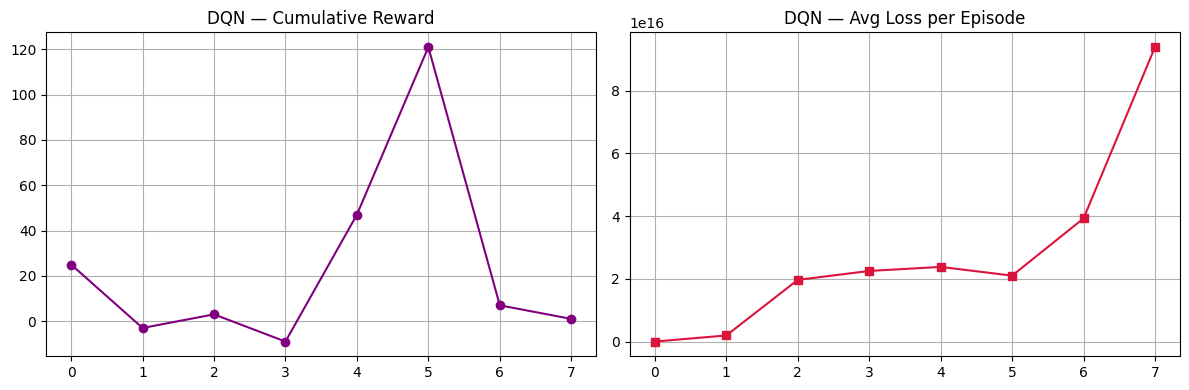


✅ DQN complete.


In [ ]:
# ============================================================
# MODEL 6: Deep Q-Network (DQN) — RL for Image Classification
#
# RL framing:
#   State   : image features (from frozen MobileNetV2 encoder)
#   Action  : 0 = predict GOOD, 1 = predict DEFECTIVE
#   Reward  : +1 correct, -1 wrong
#   Agent   : DQN with experience replay & target network
# ============================================================
import os, random, warnings; warnings.filterwarnings('ignore')
from collections import deque
import numpy as np, tensorflow as tf
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

MODEL_NAME = "DQN"

# ── Hyper-params ───────────────────────────────────────────
FEATURE_DIM  = 1280          # MobileNetV2 GlobalAvgPool output dim
N_ACTIONS    = 2
GAMMA        = 0.95
EPSILON_START= 1.0
EPSILON_MIN  = 0.05
EPSILON_DECAY= 0.995
LR           = 1e-3
MEMORY_SIZE  = 5_000
BATCH_RL     = 64
TRAIN_EPOCHS = 8             # episodes over dataset

# 1. ── Encoder: frozen MobileNetV2 ────────────────────────
base = tf.keras.applications.MobileNetV2(
    include_top=False, weights='imagenet',
    input_shape=(224,224,3), pooling='avg')
base.trainable = False
print(f"Feature encoder output dim: {FEATURE_DIM}")

preprocess_fn = tf.keras.applications.mobilenet_v2.preprocess_input

def extract_features(img_batch_norm):
    """img_batch_norm: float32 [0,1] → features"""
    x = preprocess_fn(img_batch_norm * 255.)
    return base(x, training=False).numpy()

# 2. ── Data (feature extraction pass) ─────────────────────
train_ds, val_ds, test_ds, _ = make_datasets(batch_size=64)

print("Extracting train features …")
X_train, Y_train = [], []
for imgs, labels in train_ds:
    X_train.append(extract_features(imgs))
    Y_train.extend(labels.numpy().flatten().astype(int))
X_train = np.vstack(X_train).astype(np.float32)
Y_train = np.array(Y_train, dtype=int)

print("Extracting test features …")
X_test, Y_test = [], []
for imgs, labels in test_ds:
    X_test.append(extract_features(imgs))
    Y_test.extend(labels.numpy().flatten().astype(int))
X_test = np.vstack(X_test).astype(np.float32)
Y_test = np.array(Y_test, dtype=int)
print(f"Train:{len(X_train)}  Test:{len(X_test)}")

# 3. ── Q-Network ───────────────────────────────────────────
def build_q_network(input_dim=FEATURE_DIM, n_actions=N_ACTIONS):
    m = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(input_dim,)),
        tf.keras.layers.Dense(512, activation='relu'),
        tf.keras.layers.BatchNormalization(),
        tf.keras.layers.Dropout(0.3),
        tf.keras.layers.Dense(256, activation='relu'),
        tf.keras.layers.Dropout(0.2),
        tf.keras.layers.Dense(128, activation='relu'),
        tf.keras.layers.Dense(n_actions, activation='linear'),
    ], name="Q_Network")
    m.compile(optimizer=tf.keras.optimizers.Adam(LR),
              loss='mse')
    return m

q_net     = build_q_network()
target_net= build_q_network()
target_net.set_weights(q_net.get_weights())
q_net.summary()

# 4. ── Replay buffer ───────────────────────────────────────
memory = deque(maxlen=MEMORY_SIZE)

def remember(state, action, reward, next_state, done):
    memory.append((state, action, reward, next_state, done))

def replay():
    if len(memory) < BATCH_RL:
        return 0.0
    batch = random.sample(memory, BATCH_RL)
    states      = np.array([t[0] for t in batch])
    actions     = np.array([t[1] for t in batch])
    rewards     = np.array([t[2] for t in batch], dtype=np.float32)
    next_states = np.array([t[3] for t in batch])
    dones       = np.array([t[4] for t in batch], dtype=np.float32)

    q_vals      = q_net(states, training=False).numpy()
    q_next      = target_net(next_states, training=False).numpy()
    targets     = rewards + GAMMA * np.max(q_next, axis=1) * (1 - dones)
    q_vals[np.arange(BATCH_RL), actions] = targets

    loss = q_net.train_on_batch(states, q_vals)
    return loss

# 5. ── Training loop ───────────────────────────────────────
epsilon = EPSILON_START
ep_rewards, ep_losses = [], []

for episode in range(TRAIN_EPOCHS):
    idx_shuffle = np.random.permutation(len(X_train))
    total_r, total_l, correct = 0.0, 0.0, 0

    for step, i in enumerate(idx_shuffle):
        state      = X_train[i]
        true_label = Y_train[i]

        # ε-greedy action
        if np.random.rand() < epsilon:
            action = np.random.randint(N_ACTIONS)
        else:
            q_vals = q_net(state[np.newaxis], training=False).numpy()[0]
            action = np.argmax(q_vals)

        reward = 1.0 if action == true_label else -1.0
        done   = True   # single-step MDP

        # next state: random sample (episodic classification)
        next_i     = np.random.randint(len(X_train))
        next_state = X_train[next_i]

        remember(state, action, reward, next_state, done)
        loss = replay()

        total_r += reward
        total_l += loss
        if action == true_label: correct += 1

        # Sync target every 500 steps
        if step % 500 == 0:
            target_net.set_weights(q_net.get_weights())

    epsilon = max(EPSILON_MIN, epsilon * EPSILON_DECAY)
    ep_acc  = correct / len(X_train) * 100
    ep_rewards.append(total_r)
    ep_losses.append(total_l / len(X_train))
    print(f"Episode {episode+1}/{TRAIN_EPOCHS} | "
          f"Acc:{ep_acc:.1f}%  Reward:{total_r:.0f}  ε:{epsilon:.3f}")

# 6. ── Evaluate ────────────────────────────────────────────
q_preds = q_net(X_test, training=False).numpy()
y_pred  = np.argmax(q_preds, axis=1)
acc_dqn = accuracy_score(Y_test, y_pred)

print(f"\n{'='*55}\n  {MODEL_NAME} — Test Accuracy: {acc_dqn*100:.2f}%\n{'='*55}")
print(classification_report(Y_test, y_pred, target_names=["Good","Defective"]))

cm = confusion_matrix(Y_test, y_pred)
plt.figure(figsize=(5,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Purples',
            xticklabels=["Good","Defective"],
            yticklabels=["Good","Defective"])
plt.title(f"{MODEL_NAME} — Confusion Matrix")
plt.ylabel("True"); plt.xlabel("Predicted")
plt.tight_layout(); plt.show()

# Reward / loss curves
fig, axes = plt.subplots(1,2, figsize=(12,4))
axes[0].plot(ep_rewards, marker='o', color='purple')
axes[0].set_title("DQN — Cumulative Reward"); axes[0].grid(True)
axes[1].plot(ep_losses,  marker='s', color='crimson')
axes[1].set_title("DQN — Avg Loss per Episode"); axes[1].grid(True)
plt.tight_layout(); plt.show()

ALL_RESULTS[MODEL_NAME] = acc_dqn
print(f"\n✅ {MODEL_NAME} complete.")

Reusing encoder from DQN block.
Reusing features from DQN block.


Model: "Actor"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_20 (Dense)                │ (None, 512)            │       655,872 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_20          │ (None, 512)            │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_10 (Dropout)            │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_21 (Dense)                │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_22 (Dense)                │ (None, 2)              │           514 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 789,762 (3.01 MB)

 Trainable params: 788,738 (3.01 MB)

 Non-trainable params: 1,024 (4.00 KB)

... (2 outputs left out)

 Total params: 789,505 (3.01 MB)

 Trainable params: 788,481 (3.01 MB)

 Non-trainable params: 1,024 (4.00 KB)

Episode 1/8 | Acc:55.8%  AL:-0.3126  CL:1.6569
Episode 2/8 | Acc:65.8%  AL:-0.3794  CL:0.8849
Episode 3/8 | Acc:70.2%  AL:-0.4873  CL:0.7070
Episode 4/8 | Acc:71.6%  AL:-0.2096  CL:0.6199
Episode 5/8 | Acc:72.3%  AL:-0.0369  CL:0.5422
Episode 6/8 | Acc:73.5%  AL:-0.0387  CL:0.5100
Episode 7/8 | Acc:74.5%  AL:-0.0315  CL:0.4992
Episode 8/8 | Acc:75.4%  AL:-0.0336  CL:0.4956

  ActorCritic — Test Accuracy: 76.89%
              precision    recall  f1-score   support

        Good       0.66      0.81      0.73       377
   Defective       0.86      0.74      0.80       614

    accuracy                           0.77       991
   macro avg       0.76      0.78      0.76       991
weighted avg       0.79      0.77      0.77       991



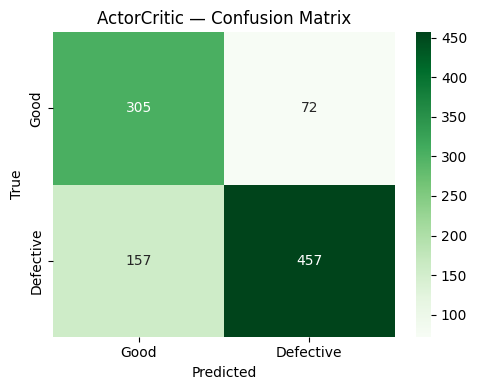

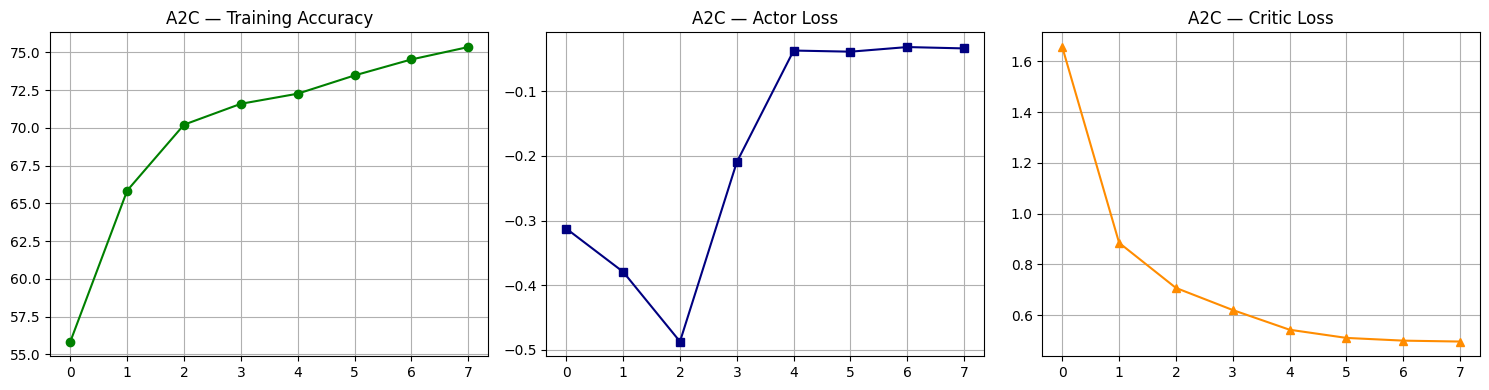


✅ ActorCritic complete.


In [ ]:
# ============================================================
# MODEL 7: Actor-Critic (A2C) — RL for Image Classification
#
# RL framing (same as DQN):
#   State  : MobileNetV2 image features
#   Action : 0=Good, 1=Defective
#   Reward : +1 correct, -1 wrong
#   Actor  : policy π(a|s) — softmax over actions
#   Critic : value  V(s)   — scalar baseline
# ============================================================
import os, warnings; warnings.filterwarnings('ignore')
import numpy as np, tensorflow as tf
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

MODEL_NAME  = "ActorCritic"
GAMMA       = 0.99
LR_ACTOR    = 3e-4
LR_CRITIC   = 5e-4
TRAIN_EPOCHS= 8
ENTROPY_COEF= 0.01     # encourage exploration

# 1. ── Reuse frozen encoder (or rebuild if needed) ─────────
try:
    _ = base   # from DQN block
    print("Reusing encoder from DQN block.")
except NameError:
    base = tf.keras.applications.MobileNetV2(
        include_top=False, weights='imagenet',
        input_shape=(224,224,3), pooling='avg')
    base.trainable = False
    preprocess_fn = tf.keras.applications.mobilenet_v2.preprocess_input
    def extract_features(img_batch_norm):
        x = preprocess_fn(img_batch_norm * 255.)
        return base(x, training=False).numpy()

# Reuse features if already extracted
try:
    _ = X_train
    print("Reusing features from DQN block.")
except NameError:
    train_ds, val_ds, test_ds, _ = make_datasets(batch_size=64)
    print("Extracting train features …")
    X_train, Y_train = [], []
    for imgs, labels in train_ds:
        X_train.append(extract_features(imgs))
        Y_train.extend(labels.numpy().flatten().astype(int))
    X_train = np.vstack(X_train).astype(np.float32)
    Y_train = np.array(Y_train, dtype=int)
    print("Extracting test features …")
    X_test, Y_test = [], []
    for imgs, labels in test_ds:
        X_test.append(extract_features(imgs))
        Y_test.extend(labels.numpy().flatten().astype(int))
    X_test = np.vstack(X_test).astype(np.float32)
    Y_test = np.array(Y_test, dtype=int)

FEAT_DIM = X_train.shape[1]

# 2. ── Actor & Critic networks ────────────────────────────
def build_actor(input_dim):
    return tf.keras.Sequential([
        tf.keras.layers.Input(shape=(input_dim,)),
        tf.keras.layers.Dense(512, activation='relu'),
        tf.keras.layers.BatchNormalization(),
        tf.keras.layers.Dropout(0.3),
        tf.keras.layers.Dense(256, activation='relu'),
        tf.keras.layers.Dense(2, activation='softmax'),
    ], name="Actor")

def build_critic(input_dim):
    return tf.keras.Sequential([
        tf.keras.layers.Input(shape=(input_dim,)),
        tf.keras.layers.Dense(512, activation='relu'),
        tf.keras.layers.BatchNormalization(),
        tf.keras.layers.Dropout(0.3),
        tf.keras.layers.Dense(256, activation='relu'),
        tf.keras.layers.Dense(1,   activation='linear'),
    ], name="Critic")

actor  = build_actor(FEAT_DIM)
critic = build_critic(FEAT_DIM)
actor.summary(); critic.summary()

actor_opt  = tf.keras.optimizers.Adam(LR_ACTOR)
critic_opt = tf.keras.optimizers.Adam(LR_CRITIC)

# 3. ── A2C update step ────────────────────────────────────
@tf.function
def a2c_update(states, actions, returns):
    with tf.GradientTape() as tape_a, tf.GradientTape() as tape_c:
        probs   = actor(states, training=True)        # (B,2)
        values  = tf.squeeze(critic(states, training=True), axis=1)  # (B,)

        advantages = returns - tf.stop_gradient(values)  # (B,)

        # Actor loss: policy gradient + entropy bonus
        log_probs  = tf.math.log(probs + 1e-8)
        idx        = tf.stack([tf.range(tf.shape(actions)[0]), actions], axis=1)
        sel_log    = tf.gather_nd(log_probs, idx)
        entropy    = -tf.reduce_sum(probs * log_probs, axis=1)
        actor_loss = -tf.reduce_mean(sel_log * advantages + ENTROPY_COEF * entropy)

        # Critic loss: MSE
        critic_loss = tf.reduce_mean(tf.square(returns - values))

    g_a = tape_a.gradient(actor_loss,  actor.trainable_variables)
    g_c = tape_c.gradient(critic_loss, critic.trainable_variables)
    actor_opt.apply_gradients(zip(g_a, actor.trainable_variables))
    critic_opt.apply_gradients(zip(g_c, critic.trainable_variables))
    return actor_loss, critic_loss

# 4. ── Training loop (mini-batch episodic A2C) ─────────────
MINI_BATCH = 256
ep_a_losses, ep_c_losses, ep_accs = [], [], []

for episode in range(TRAIN_EPOCHS):
    idx_shuffle = np.random.permutation(len(X_train))
    total_correct, total_al, total_cl = 0, 0.0, 0.0
    n_batches = 0

    for start in range(0, len(X_train), MINI_BATCH):
        idx_b   = idx_shuffle[start:start+MINI_BATCH]
        states  = X_train[idx_b]
        labels  = Y_train[idx_b]

        # Single-step returns: reward = +1 correct, -1 wrong
        probs_np = actor(states, training=False).numpy()
        actions  = np.array([np.random.choice(2, p=p) for p in probs_np], dtype=np.int32)
        rewards  = np.where(actions == labels, 1.0, -1.0).astype(np.float32)

        # For one-step MDP, G_t = r_t  (no bootstrapping needed)
        returns  = tf.constant(rewards, dtype=tf.float32)

        al, cl = a2c_update(
            tf.constant(states, tf.float32),
            tf.constant(actions, tf.int32),
            returns)

        total_correct += np.sum(actions == labels)
        total_al += al.numpy()
        total_cl += cl.numpy()
        n_batches += 1

    ep_acc = total_correct / len(X_train) * 100
    ep_a_losses.append(total_al / n_batches)
    ep_c_losses.append(total_cl / n_batches)
    ep_accs.append(ep_acc)
    print(f"Episode {episode+1}/{TRAIN_EPOCHS} | "
          f"Acc:{ep_acc:.1f}%  AL:{total_al/n_batches:.4f}  CL:{total_cl/n_batches:.4f}")

# 5. ── Evaluate ────────────────────────────────────────────
probs_test = actor(X_test, training=False).numpy()
y_pred_ac  = np.argmax(probs_test, axis=1)
acc_ac     = accuracy_score(Y_test, y_pred_ac)

print(f"\n{'='*55}\n  {MODEL_NAME} — Test Accuracy: {acc_ac*100:.2f}%\n{'='*55}")
print(classification_report(Y_test, y_pred_ac, target_names=["Good","Defective"]))

cm = confusion_matrix(Y_test, y_pred_ac)
plt.figure(figsize=(5,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Greens',
            xticklabels=["Good","Defective"],
            yticklabels=["Good","Defective"])
plt.title(f"{MODEL_NAME} — Confusion Matrix")
plt.ylabel("True"); plt.xlabel("Predicted")
plt.tight_layout(); plt.show()

# Training curves
fig, axes = plt.subplots(1,3, figsize=(15,4))
axes[0].plot(ep_accs,    marker='o', color='green')
axes[0].set_title("A2C — Training Accuracy"); axes[0].grid(True)
axes[1].plot(ep_a_losses,marker='s', color='navy')
axes[1].set_title("A2C — Actor Loss"); axes[1].grid(True)
axes[2].plot(ep_c_losses,marker='^', color='darkorange')
axes[2].set_title("A2C — Critic Loss"); axes[2].grid(True)
plt.tight_layout(); plt.show()

ALL_RESULTS[MODEL_NAME] = acc_ac
print(f"\n✅ {MODEL_NAME} complete.")


       MODEL COMPARISON TABLE
         Model            Type  Accuracy
1     ResNet50  CNN (Transfer)     90.92
2  MobileNetV2  CNN (Transfer)     86.78
3      CNN_GRU       CNN + RNN     81.94
4    CustomCNN    CNN (Custom)     81.74
5     CNN_LSTM       CNN + RNN     81.63
6  ActorCritic              RL     76.89
7          DQN              RL     48.13


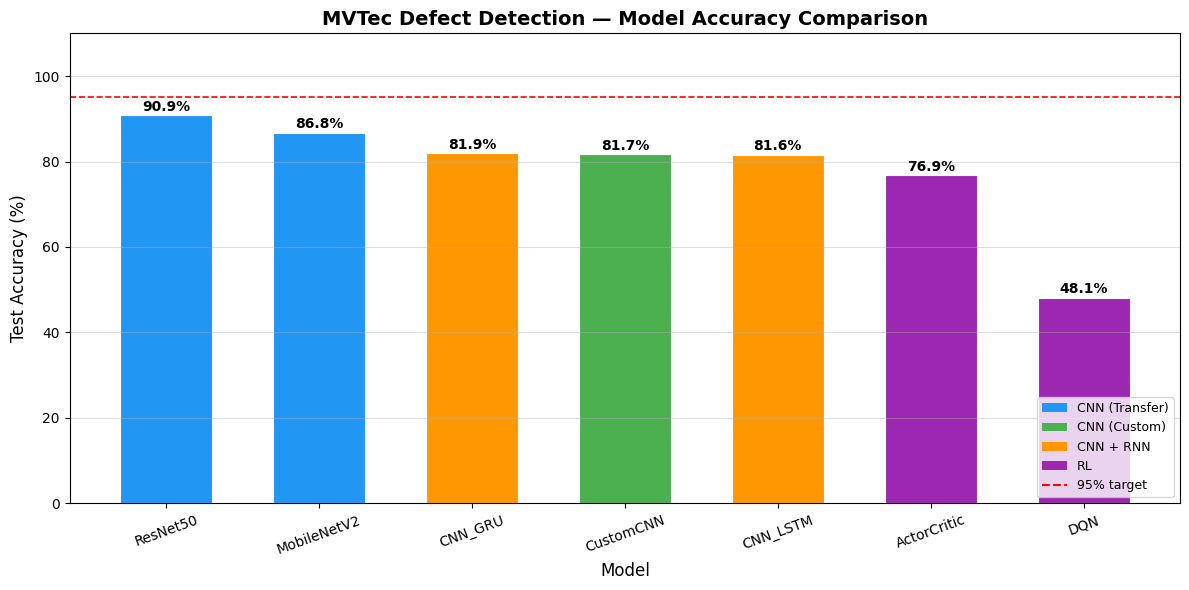

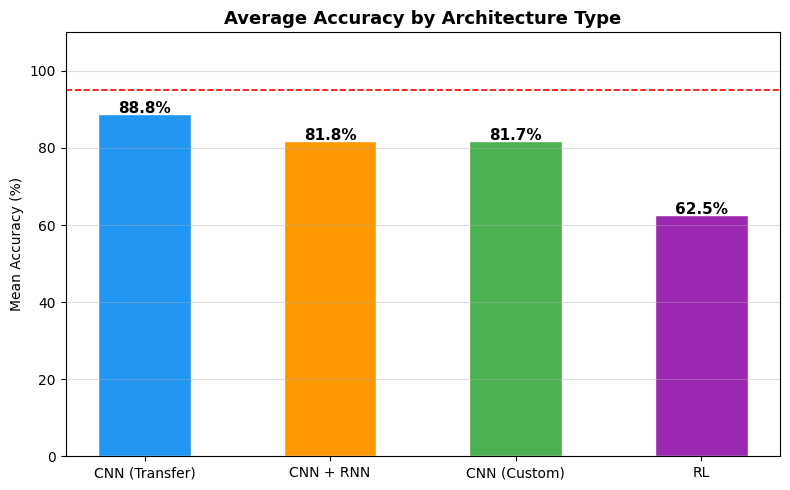

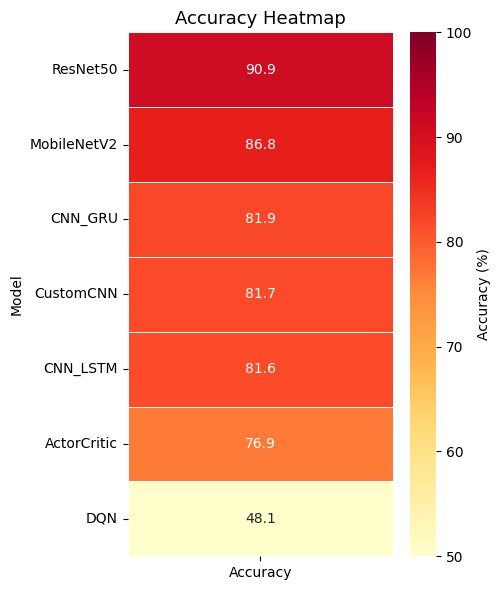


🏆 Best model: ResNet50 (90.92%)
📊 Comparison chart saved → /content/model_comparison.png


In [ ]:
# ============================================================
# FINAL COMPARISON — Run after ALL 7 models complete
# ============================================================
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns

# ── Build results table ────────────────────────────────────
# ALL_RESULTS = { model_name: test_accuracy (float 0-1) }
# Populate any missing entries manually if a block was skipped:
# ALL_RESULTS["ResNet50"] = 0.97  # example

model_types = {
    "ResNet50"    : "CNN (Transfer)",
    "MobileNetV2" : "CNN (Transfer)",
    "CustomCNN"   : "CNN (Custom)",
    "CNN_LSTM"    : "CNN + RNN",
    "CNN_GRU"     : "CNN + RNN",
    "DQN"         : "RL",
    "ActorCritic" : "RL",
}

rows = []
for name, acc in ALL_RESULTS.items():
    rows.append({
        "Model"    : name,
        "Type"     : model_types.get(name, "—"),
        "Accuracy" : round(acc * 100, 2),
    })

df = pd.DataFrame(rows).sort_values("Accuracy", ascending=False).reset_index(drop=True)
df.index += 1  # rank from 1

print("\n" + "="*55)
print("       MODEL COMPARISON TABLE")
print("="*55)
print(df.to_string())
print("="*55)

# ── Bar chart ─────────────────────────────────────────────
palette = {
    "CNN (Transfer)" : "#2196F3",
    "CNN (Custom)"   : "#4CAF50",
    "CNN + RNN"      : "#FF9800",
    "RL"             : "#9C27B0",
}
colors = [palette[t] for t in df["Type"]]

fig, ax = plt.subplots(figsize=(12, 6))
bars = ax.bar(df["Model"], df["Accuracy"], color=colors,
              edgecolor='white', linewidth=0.8, width=0.6)

# Value labels on bars
for bar, acc in zip(bars, df["Accuracy"]):
    ax.text(bar.get_x() + bar.get_width()/2,
            bar.get_height() + 0.3,
            f"{acc:.1f}%", ha='center', va='bottom',
            fontsize=10, fontweight='bold')

ax.set_ylim(0, 110)
ax.axhline(95, color='red', linestyle='--', linewidth=1.2, label='95% target')
ax.set_xlabel("Model", fontsize=12)
ax.set_ylabel("Test Accuracy (%)", fontsize=12)
ax.set_title("MVTec Defect Detection — Model Accuracy Comparison", fontsize=14, fontweight='bold')
ax.tick_params(axis='x', rotation=20)
ax.grid(axis='y', alpha=0.4)

# Legend for model types
from matplotlib.patches import Patch
legend_elements = [Patch(facecolor=c, label=l) for l, c in palette.items()]
legend_elements.append(plt.Line2D([0],[0], color='red', linestyle='--', label='95% target'))
ax.legend(handles=legend_elements, loc='lower right', fontsize=9)

plt.tight_layout()
plt.savefig("/content/model_comparison.png", dpi=150, bbox_inches='tight')
plt.show()

# ── Grouped comparison by type ────────────────────────────
fig, ax = plt.subplots(figsize=(8,5))
type_means = df.groupby("Type")["Accuracy"].mean().sort_values(ascending=False)
type_colors = [palette[t] for t in type_means.index]
bars2 = ax.bar(type_means.index, type_means.values, color=type_colors,
               edgecolor='white', width=0.5)
for bar, val in zip(bars2, type_means.values):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.3,
            f"{val:.1f}%", ha='center', fontsize=11, fontweight='bold')
ax.set_ylim(0, 110)
ax.axhline(95, color='red', linestyle='--', linewidth=1.2)
ax.set_title("Average Accuracy by Architecture Type", fontsize=13, fontweight='bold')
ax.set_ylabel("Mean Accuracy (%)")
ax.grid(axis='y', alpha=0.4)
plt.tight_layout(); plt.show()

# ── Heatmap-style summary ─────────────────────────────────
fig, ax = plt.subplots(figsize=(5,6))
heat_data = df[["Accuracy"]].set_index(df["Model"])
sns.heatmap(heat_data, annot=True, fmt=".1f", cmap="YlOrRd",
            linewidths=0.5, ax=ax, vmin=50, vmax=100,
            cbar_kws={"label": "Accuracy (%)"})
ax.set_title("Accuracy Heatmap", fontsize=13)
plt.tight_layout(); plt.show()

print("\n🏆 Best model:", df.iloc[0]["Model"],
      f"({df.iloc[0]['Accuracy']}%)")
print("📊 Comparison chart saved → /content/model_comparison.png")